# DS-A4 Model Comparison and Calibration
## 1. Data and frozen protocol
Use the [sklearn Breast Cancer Wisconsin dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html): 569 samples, 30 numeric features; malignant = 1. It is small, complete, and suitable for comparing classification probabilities.

Freeze an 80/20 stratified split and five training folds (seed 42). Each model gets one fixed configuration and the same metrics. Select the model by pooled out-of-fold AP, then Brier for a tie. Choose the threshold from training predictions using illustrative FN cost 5, FP cost 1, and review capacity 40%. Test data are used only after these choices.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.metrics import precision_recall_curve, roc_curve, confusion_matrix
from sklearn.calibration import calibration_curve

SEED, B, FN_COST, CAPACITY = 42, 1000, 5, 0.40
METRICS = ['AP', 'ROC_AUC', 'Brier', 'ECE']
THRESHOLDS = np.arange(102) / 100
pd.options.display.float_format = '{:.4f}'.format
plt.rcParams.update({'figure.figsize': (7, 3.7), 'figure.dpi': 120, 'font.size': 10})
data = load_breast_cancer(as_frame=True)
X, y = data.data, 1 - data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_train, y_train))
print('sklearn:', sklearn.__version__, '| data:', X.shape, '| missing:', X.isna().sum().sum())
print('Train:', len(y_train), '| test:', len(y_test), '| malignant:', int(y.sum()))

sklearn: 1.7.2 | data: (569, 30) | missing: 0
Train: 455 | test: 114 | malignant: 212


## 2. Model comparison
Logistic regression is the strong simple baseline. Scaling is fitted inside its pipeline. AP summarizes the precision-recall curve; higher AP/ROC AUC and lower Brier/ECE are better. ECE uses ten equal-width probability bins.

In [2]:
def scores(actual, probability):
    actual, probability = np.asarray(actual), np.asarray(probability)
    bins = np.minimum((probability * 10).astype(int), 9)
    ece = sum(np.mean(bins == b) * abs(actual[bins == b].mean() - probability[bins == b].mean())
              for b in np.unique(bins))
    return [average_precision_score(actual, probability), roc_auc_score(actual, probability),
            brier_score_loss(actual, probability), ece]

models = {
    'Logistic': make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)),
    'Tree': DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=SEED),
    'Forest': RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=5,
                                     random_state=SEED, n_jobs=1)
}
oof = pd.DataFrame(index=X_train.index)
for name, model in models.items():
    oof[name] = cross_val_predict(model, X_train, y_train, cv=folds,
                                  method='predict_proba')[:, 1]
cv_results = pd.DataFrame({name: scores(y_train, oof[name]) for name in models}, index=METRICS).T
selected = cv_results.sort_values(['AP', 'Brier'], ascending=[False, True]).index[0]
display(cv_results)
print('Selected:', selected)

,AP,ROC_AUC,Brier,ECE
Logistic,0.9943,0.9953,0.0191,0.0173
Tree,0.9313,0.9472,0.0637,0.0432
Forest,0.9849,0.9877,0.0368,0.0313


Selected: Logistic


## 3. Threshold decision
Minimize `(5 FN + FP) / n` subject to the training review rate being at most 40%. Ties favor fewer reviews, then a higher threshold. Thresholds range from 0 to 1.01 in steps of 0.01; 1.01 means review nobody.

In [3]:
def cost_curve(actual, probability, fn_cost):
    actual, probability = np.asarray(actual), np.asarray(probability)
    rows = []
    for threshold in THRESHOLDS:
        decision = probability >= threshold
        fp = np.sum(decision & (actual == 0))
        fn = np.sum(~decision & (actual == 1))
        rows.append([threshold, decision.mean(), (fn_cost * fn + fp) / len(actual)])
    return pd.DataFrame(rows, columns=['threshold', 'review_rate', 'cost'])

def choose(curve, capacity):
    return curve[curve['review_rate'] <= capacity].sort_values(
        ['cost', 'review_rate', 'threshold'], ascending=[True, True, False]).iloc[0]

curve = cost_curve(y_train, oof[selected], FN_COST)
policy = choose(curve, CAPACITY)
threshold = policy['threshold']
display(policy.to_frame('training OOF'))

,training OOF
threshold,0.3000
review_rate,0.3824
cost,0.0615


,AP,ROC_AUC,Brier,ECE
Logistic,0.9943,0.9960,0.0213,0.0302
Tree,0.9349,0.9527,0.0632,0.0533
Forest,0.9916,0.9944,0.0341,0.0516


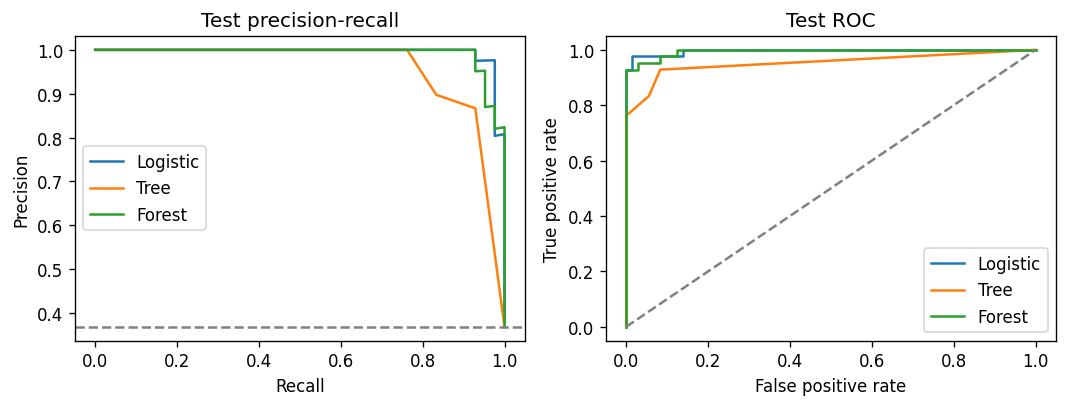

In [4]:
fitted = {name: clone(model).fit(X_train, y_train) for name, model in models.items()}
test = pd.DataFrame({name: model.predict_proba(X_test)[:, 1]
                      for name, model in fitted.items()}, index=X_test.index)
test_results = pd.DataFrame({name: scores(y_test, test[name]) for name in models}, index=METRICS).T
display(test_results)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for name in models:
    precision, recall, _ = precision_recall_curve(y_test, test[name])
    fpr, tpr, _ = roc_curve(y_test, test[name])
    axes[0].plot(recall, precision, label=name)
    axes[1].plot(fpr, tpr, label=name)
axes[0].axhline(y_test.mean(), color='gray', linestyle='--')
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='Test precision-recall', xlabel='Recall', ylabel='Precision')
axes[1].set(title='Test ROC', xlabel='False positive rate', ylabel='True positive rate')
for ax in axes: ax.legend()
fig.tight_layout()
plt.show()

## 4. Calibration and paired intervals
Use 1,000 paired, class-stratified bootstrap resamples of the test rows for 95% percentile intervals. The same resampled rows are used for all models; intervals describe test-sample uncertainty for fixed fitted models. ECE depends on binning; Brier also reflects discrimination.

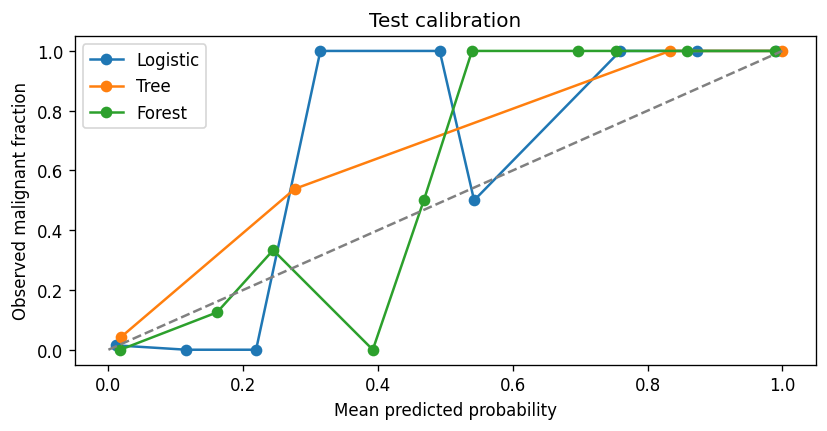

,Model,Metric,Value,Low,High
0,Logistic,AP,0.9943,0.9821,1.0000
1,Logistic,ROC_AUC,0.9960,0.9868,1.0000
2,Logistic,Brier,0.0213,0.0066,0.0414
3,Logistic,ECE,0.0302,0.0203,0.0607
4,Tree,AP,0.9349,0.8740,0.9811
5,Tree,ROC_AUC,0.9527,0.9019,0.9908
6,Tree,Brier,0.0632,0.0313,0.0983
7,Tree,ECE,0.0533,0.0231,0.0947
8,Forest,AP,0.9916,0.9771,1.0000
9,Forest,ROC_AUC,0.9944,0.9838,1.0000


,Difference,Metric,Value,Low,High
0,Tree - Logistic,AP,-0.0594,-0.1141,-0.0164
1,Tree - Logistic,ROC_AUC,-0.0433,-0.0888,-0.0086
2,Tree - Logistic,Brier,0.0419,0.0145,0.0732
3,Tree - Logistic,ECE,0.0231,-0.0137,0.0550
4,Forest - Logistic,AP,-0.0026,-0.0138,0.0062
5,Forest - Logistic,ROC_AUC,-0.0017,-0.0093,0.0046
6,Forest - Logistic,Brier,0.0127,-0.0033,0.0313
7,Forest - Logistic,ECE,0.0213,0.0010,0.0504


In [5]:
fig, ax = plt.subplots()
for name in models:
    observed, predicted = calibration_curve(y_test, test[name], n_bins=10, strategy='uniform')
    ax.plot(predicted, observed, 'o-', label=name)
ax.plot([0, 1], [0, 1], '--', color='gray')
ax.set(title='Test calibration', xlabel='Mean predicted probability', ylabel='Observed malignant fraction')
ax.legend()
fig.tight_layout()
plt.show()

rng = np.random.default_rng(SEED)
y_test_array = y_test.to_numpy()
class_rows = [np.flatnonzero(y_test_array == k) for k in [0, 1]]
boot = np.empty((B, len(models), len(METRICS)))
for b in range(B):
    rows = np.concatenate([rng.choice(group, len(group), replace=True) for group in class_rows])
    for j, name in enumerate(models):
        boot[b, j] = scores(y_test_array[rows], test[name].to_numpy()[rows])
interval_rows, paired_rows = [], []
for j, name in enumerate(models):
    for k, metric in enumerate(METRICS):
        low, high = np.quantile(boot[:, j, k], [0.025, 0.975])
        interval_rows.append([name, metric, test_results.loc[name, metric], low, high])
        if j > 0:
            low, high = np.quantile(boot[:, j, k] - boot[:, 0, k], [0.025, 0.975])
            paired_rows.append([name + ' - Logistic', metric,
                                test_results.loc[name, metric] - test_results.loc['Logistic', metric], low, high])
intervals = pd.DataFrame(interval_rows, columns=['Model', 'Metric', 'Value', 'Low', 'High'])
paired = pd.DataFrame(paired_rows, columns=['Difference', 'Metric', 'Value', 'Low', 'High'])
display(intervals)
display(paired)

## 5. Cost and capacity sensitivity
For each alternative cost/capacity pair, choose a threshold on training OOF predictions, then report its test outcomes. Capacity is an expected review-rate limit from training; the test rate may differ.

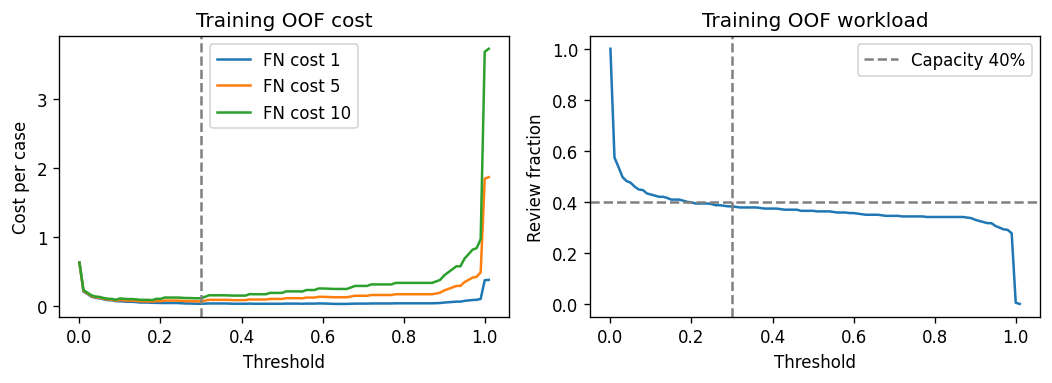

,FN_cost,capacity,threshold,OOF_review,OOF_cost,Test_review,Test_FN,Test_FP,Test_cost
0,1,0.2000,1.0000,0.0044,0.3692,0.0000,42,0,0.3684
1,1,0.3000,0.9600,0.2989,0.0747,0.2632,12,0,0.1053
2,1,0.4000,0.6600,0.3495,0.0242,0.3333,4,0,0.0351
3,5,0.2000,1.0000,0.0044,1.8462,0.0000,42,0,1.8421
4,5,0.3000,0.9600,0.2989,0.3736,0.2632,12,0,0.5263
5,5,0.4000,0.3000,0.3824,0.0615,0.3684,1,1,0.0526
6,10,0.2000,1.0000,0.0044,3.6923,0.0000,42,0,3.6842
7,10,0.3000,0.9600,0.2989,0.7473,0.2632,12,0,1.0526
8,10,0.4000,0.2000,0.3978,0.0967,0.3947,1,4,0.1228


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for cost in [1, 5, 10]:
    alternative = cost_curve(y_train, oof[selected], cost)
    axes[0].plot(alternative['threshold'], alternative['cost'], label=f'FN cost {cost}')
axes[0].axvline(threshold, color='gray', linestyle='--')
axes[0].set(title='Training OOF cost', xlabel='Threshold', ylabel='Cost per case')
axes[0].legend()
axes[1].plot(curve['threshold'], curve['review_rate'])
axes[1].axhline(CAPACITY, color='gray', linestyle='--', label='Capacity 40%')
axes[1].axvline(threshold, color='gray', linestyle='--')
axes[1].set(title='Training OOF workload', xlabel='Threshold', ylabel='Review fraction')
axes[1].legend()
fig.tight_layout()
plt.show()

sensitivity_rows = []
for cost in [1, 5, 10]:
    for capacity in [0.2, 0.3, 0.4]:
        choice = choose(cost_curve(y_train, oof[selected], cost), capacity)
        decision = test[selected].to_numpy() >= choice['threshold']
        tn, fp, fn, tp = confusion_matrix(y_test, decision, labels=[0, 1]).ravel()
        sensitivity_rows.append([cost, capacity, choice['threshold'], choice['review_rate'],
            choice['cost'], decision.mean(), fn, fp, (cost * fn + fp) / len(y_test)])
sensitivity = pd.DataFrame(sensitivity_rows, columns=['FN_cost', 'capacity', 'threshold',
    'OOF_review', 'OOF_cost', 'Test_review', 'Test_FN', 'Test_FP', 'Test_cost'])
display(sensitivity)

## 6. Slices and failures
Define small/large mean-radius groups using the training median. Apply the frozen model and threshold to both groups. A false negative is a malignant case that is not flagged; a false positive is a benign case flagged for review.

In [7]:
radius_cut = X_train['mean radius'].median()
results = test.add_suffix('_probability').copy()
results.insert(0, 'actual', y_test)
results['radius_slice'] = np.where(X_test['mean radius'] <= radius_cut, 'Small', 'Large')
results['selected_probability'] = test[selected]
results['decision'] = (test[selected] >= threshold).astype(int)
results['failure'] = np.select(
    [(results.actual == 1) & (results.decision == 0),
     (results.actual == 0) & (results.decision == 1)], ['FN', 'FP'], default='Correct')
slice_rows = []
for group, frame in results.groupby('radius_slice'):
    fn, fp = (frame.failure == 'FN').sum(), (frame.failure == 'FP').sum()
    slice_rows.append([group, len(frame), frame.actual.sum(), fn, fp,
                       (FN_COST * fn + fp) / len(frame)])
slices = pd.DataFrame(slice_rows, columns=['Radius', 'n', 'Positive', 'FN', 'FP', 'Cost'])
display(slices)
display(results['failure'].value_counts().to_frame('n'))
# The largest probability error is a counterexample to perfect individual reliability.
results['probability_error'] = abs(results.actual - results.selected_probability)
errors = results[results.failure != 'Correct'].nlargest(3, 'probability_error')
display(errors[['actual', 'selected_probability', 'decision', 'failure', 'radius_slice']])
print('Frozen decision:', selected, '| threshold:', threshold, '| radius median:', radius_cut)
print('Test review:', results.decision.mean(), '| cost:',
      (FN_COST * (results.failure == 'FN').sum() + (results.failure == 'FP').sum()) / len(results))

,Radius,n,Positive,FN,FP,Cost
0,Large,58,40,1,1,0.1034
1,Small,56,2,0,0,0.0000


,n
failure,
Correct,112
FP,1
FN,1


,actual,selected_probability,decision,failure,radius_slice
73,1,0.0614,0,FN,Large
455,0,0.5092,1,FP,Large


Frozen decision: Logistic | threshold: 0.3 | radius median: 13.34
Test review: 0.3684210526315789 | cost: 0.05263157894736842


## 7. Conclusion and reproduction
Logistic is preferred: the more complex models did not improve AP or Brier. At threshold 0.30, the test review rate is 36.8%, with one FN and one FP. Forest minus Logistic AP is -0.0026 (paired 95% interval -0.0138 to 0.0062), so this comparison does not establish a difference in ranking performance.

Both errors are in the large-radius group (40 positives in 58 rows); the small-radius group has only two positives in 56 rows. Row 73 is a counterexample: a malignant case receives probability 0.0614 and is missed. At 20% capacity, the coarse threshold grid selects 1.00 and underuses capacity; this poor configuration is retained.

The small test set, one cohort, sparse calibration bins, and unequal subgroup class mixes limit conclusions. Costs and capacity are illustrative. Use Python 3.12 and requirements.txt, then restart the kernel and run all cells; results.csv is regenerated.

In [8]:
train_raw = oof.add_suffix('_probability').copy()
train_raw.insert(0, 'actual', y_train)
train_raw['radius_slice'] = np.where(X_train['mean radius'] <= radius_cut, 'Small', 'Large')
train_raw['selected_probability'] = oof[selected]
train_raw['decision'] = (oof[selected] >= threshold).astype(int)
train_raw['failure'] = np.select(
    [(train_raw.actual == 1) & (train_raw.decision == 0),
     (train_raw.actual == 0) & (train_raw.decision == 1)], ['FN', 'FP'], default='Correct')
train_raw['probability_error'] = abs(train_raw.actual - train_raw.selected_probability)
raw = pd.concat([train_raw.assign(split='train_oof'), results.assign(split='test')])
raw['selected_model'], raw['threshold'] = selected, threshold
raw.rename_axis('sample_id').to_csv('results.csv', float_format='%.10f')
assert len(raw) == len(X) and X_train.index.intersection(X_test.index).empty
print('Saved paired OOF/test predictions:', raw.shape)

Saved paired OOF/test predictions: (569, 12)
